# Kiểm tra và xem dữ liệu BraTS-Africa

Notebook tải bản BraTS-Africa 224x224 từ Kaggle, kiểm tra 146 NPZ và metadata,
rồi vẽ bốn MRI cùng mask Whole Tumor. Hai nhóm 95 glioma và 51 u khác được giữ riêng.

Chạy lần lượt các ô bằng runtime CPU. Khi được yêu cầu, chọn ZIP bộ mã và kaggle.json.
Dữ liệu tải vào `/content`, bảng kiểm tra và hình lưu trên Google Drive.
Các hình dùng ground truth đã resize, chưa có dự đoán mô hình.


## 1. Chuẩn bị mã nguồn

Chọn `africa_midterm.zip` khi Colab yêu cầu. Cell giải nén bộ mã và chuyển về thư mục dự án.
Các bước xử lý chính nằm trong `src/preprocess` và `src/viz`, notebook chỉ cấu hình và gọi lệnh.
Nếu runtime đã có bộ mã mới thì dùng lại thư mục đó.


In [1]:
# 1. Mở bộ mã và chuyển về thư mục làm việc.

import os
import sys
import json
import subprocess
import zipfile
from pathlib import Path

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

required_modules = [
    'src/preprocess/check_africa_npz.py',
    'src/viz/africa_samples.py'
]
candidates = [Path.cwd(), Path.cwd().parent, Path('/content/brats-africa-workspace')]
REPO_DIR = next(
    (path for path in candidates if all((path / name).is_file() for name in required_modules)),
    None
)

if REPO_DIR is None and IN_COLAB:
    from google.colab import files
    uploaded = files.upload()
    assert 'africa_midterm.zip' in uploaded, 'Chọn đúng bộ mã africa_midterm.zip mới.'
    REPO_DIR = Path('/content/brats-africa-workspace')
    REPO_DIR.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile('africa_midterm.zip') as archive:
        for member in archive.infolist():
            target = (REPO_DIR / member.filename).resolve()
            assert target.is_relative_to(REPO_DIR.resolve()), 'Đường dẫn trong ZIP không hợp lệ.'
        archive.extractall(REPO_DIR)
    del uploaded

assert REPO_DIR is not None, 'Cần mở notebook từ bộ mã đã giải nén.'
assert all((REPO_DIR / name).is_file() for name in required_modules), 'Cần tải lại ZIP bộ mã mới.'
REPO_DIR = REPO_DIR.resolve()
os.chdir(REPO_DIR)
os.environ['MPLCONFIGDIR'] = str(REPO_DIR / '.mplconfig')
print('Thư mục làm việc:', REPO_DIR)

Thư mục làm việc: /content/brats-africa-workspace


## 2. Cài thư viện

Cài các thư viện dùng để tải Kaggle, đọc NPZ và vẽ ảnh.
Hàm `run_module` giúp chạy các lệnh bằng đúng Python của runtime và dừng khi có lỗi.
Nếu Colab yêu cầu khởi động lại runtime, thực hiện rồi chạy lại từ ô 1.


In [2]:
# 2. Cài thư viện và tạo hàm gọi các module của dự án.

subprocess.run(
    [sys.executable, '-m', 'pip', 'install', '-q', '-r', 'requirements-africa.txt'],
    check=True
)

def run_module(module, *args):
    subprocess.run(
        [sys.executable, '-m', module, *map(str, args)],
        check=True,
        cwd=REPO_DIR
    )

## 3. Cấu hình dữ liệu và thư mục kết quả

Dataset đã có NPZ và metadata nên không cần tải lại NIfTI gốc.
Kết quả mỗi lần chạy được lưu vào thư mục riêng trên Drive.
Dữ liệu tải trong `/content` có thể mất khi runtime bị xóa, khi đó chạy lại ô tải dữ liệu.


In [3]:
# 3. Kết nối Drive và đặt các đường dẫn dùng chung.

from datetime import datetime, timezone

DATASET = 'trinhthuhuyenhuyen/brats-africa-preprocessed-224-v11'
run_name = 'africa_data_run01'

if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    PROCESSED_DIR = Path('/content/brats_africa_preprocessed_224_v11')
    OUT_DIR = Path('/content/drive/MyDrive/brats_africa_midterm') / run_name
else:
    PROCESSED_DIR = REPO_DIR / 'data/preprocessed/africa'
    OUT_DIR = REPO_DIR / 'results/africa' / run_name

CHECK_DIR = OUT_DIR / 'checks'
FIGURE_DIR = OUT_DIR / 'figures'
OUT_DIR.mkdir(parents=True, exist_ok=True)
print('Dataset:', DATASET)
print('Dữ liệu:', PROCESSED_DIR)
print('Kết quả:', OUT_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset: trinhthuhuyenhuyen/brats-africa-preprocessed-224-v11
Dữ liệu: /content/brats_africa_preprocessed_224_v11
Kết quả: /content/drive/MyDrive/brats_africa_midterm/africa_data_run01


## 4. Cấu hình Kaggle API

Chọn file `kaggle.json` của tài khoản có quyền đọc dataset.
Cell chỉ yêu cầu upload khi runtime chưa có file xác thực, nội dung khóa không được in ra.
Dataset đang riêng tư, tài khoản khác cần được cấp quyền xem trước khi tải.


In [4]:
# 4. Lưu thông tin xác thực vào thư mục cấu hình Kaggle.

credentials = Path.home() / '.kaggle' / 'kaggle.json'

if not credentials.is_file():
    assert IN_COLAB, 'Cần cấu hình kaggle.json trước khi chạy trên máy cá nhân.'
    from google.colab import files
    uploaded = files.upload()
    assert 'kaggle.json' in uploaded, 'Chọn đúng file kaggle.json.'
    credentials.parent.mkdir(parents=True, exist_ok=True)
    credentials.write_bytes(uploaded['kaggle.json'])
    credentials.chmod(0o600)
    Path('kaggle.json').unlink(missing_ok=True)
    del uploaded

os.environ['KAGGLE_CONFIG_DIR'] = str(credentials.parent)
print('Đã cấu hình Kaggle API.')

Đã cấu hình Kaggle API.


## 5. Tải dữ liệu và kiểm tra checksum

Tải khoảng 2,45 GiB từ Kaggle, sau đó đối chiếu SHA256 của từng NPZ và metadata với báo cáo đi kèm.
Nếu đã có đủ file và checksum khớp thì dùng lại dữ liệu trong runtime.
Nếu gặp lỗi 403, kiểm tra tài khoản Kaggle đã được cấp quyền đọc dataset hay chưa.


In [5]:
# 5. Tải bản đã xử lý và kiểm tra file tải về.

run_module(
    'src.preprocess.download_africa_kaggle',
    '--dataset', DATASET,
    '--out-dir', PROCESSED_DIR
)

## 6. Kiểm tra toàn bộ NPZ và metadata

Mở lần lượt 146 ca để kiểm tra shape, dtype, giá trị hữu hạn, WT nhị phân và các cờ lát cắt.
Đối chiếu ID, nhóm và số lát giữa index với metadata, kiểm tra đủ 95 glioma và 51 u khác.
Bước này kiểm tra bản đã xử lý, không xác minh lại affine với NIfTI gốc.


In [6]:
# 6. Mở và kiểm tra dữ liệu của tất cả bệnh nhân.

run_module(
    'src.preprocess.check_africa_npz',
    '--data-dir', PROCESSED_DIR,
    '--out-dir', CHECK_DIR
)

import pandas as pd
from IPython.display import display, Image

summary = json.loads((CHECK_DIR / 'npz_check_summary.json').read_text(encoding='utf-8'))
case_checks = pd.read_csv(CHECK_DIR / 'npz_check_cases.csv')
assert summary['num_valid_cases'] == 146, 'Cần kiểm tra lại các ca chưa đạt.'
print('Số ca đã kiểm tra:', summary['num_valid_cases'])
display(case_checks.groupby('group').size().rename('num_cases').to_frame())
display(case_checks.head())

Số ca đã kiểm tra: 146


,num_cases
group,
51_OtherNeoplasms,51
95_Glioma,95


,case_id,group,num_slices_z,num_tumor_slices,num_brain_slices,wt_pixels_224,valid
0,BraTS-SSA-00009-000,51_OtherNeoplasms,155,40,147,30784,True
1,BraTS-SSA-00018-000,51_OtherNeoplasms,155,39,141,16247,True
2,BraTS-SSA-00040-000,51_OtherNeoplasms,155,116,139,373001,True
3,BraTS-SSA-00045-000,51_OtherNeoplasms,155,81,136,229619,True
4,BraTS-SSA-00062-000,51_OtherNeoplasms,155,112,134,86669,True


## 7. Xem cấu trúc một ca và thống kê WT

Mỗi ca có ảnh `[155, 4, 224, 224]` và WT `[155, 224, 224]`.
Thứ tự bốn kênh là T1, T1ce, T2, FLAIR.
Thể tích WT dưới đây được đọc từ bảng EDA tính trên NIfTI gốc đi kèm dataset,
không quy đổi trực tiếp số pixel của mask 224x224 sang mL.


In [7]:
# 7. Xem một ca và lập bảng thống kê từ EDA đi kèm.
import numpy as np

index = json.loads((PROCESSED_DIR / 'index.json').read_text(encoding='utf-8'))
case_id = index[0]['case_id']
with np.load(PROCESSED_DIR / 'cases' / f'{case_id}.npz', allow_pickle=False) as archive:
    print('Case ID:', case_id)
    for key in archive.files:
        print(key, archive[key].shape, archive[key].dtype)
    print('Giá trị mask:', np.unique(archive['masks']))

eda = pd.read_csv(PROCESSED_DIR / 'eda_africa_cases.csv')
assert len(eda) == 146 and eda['case_id'].is_unique, 'Bảng EDA thiếu ca hoặc trùng ID.'
assert set(eda['case_id']) == {row['case_id'] for row in index}, 'EDA không khớp index.'
wt_summary = eda.groupby('group')['wt_volume_ml'].agg(
    num_cases='count', wt_mean_ml='mean', wt_sd_ml='std', wt_median_ml='median'
)
wt_summary.to_csv(OUT_DIR / 'wt_volume_summary.csv')
display(wt_summary.round(2))

Case ID: BraTS-SSA-00009-000
images (155, 4, 224, 224) float16
masks (155, 224, 224) uint8
slice_has_tumor (155,) uint8
slice_has_brain (155,) uint8
Giá trị mask: [0 1]


,num_cases,wt_mean_ml,wt_sd_ml,wt_median_ml
group,,,,
51_OtherNeoplasms,51,124.67,98.45,82.80
95_Glioma,95,161.58,93.66,162.87


## 8. Vẽ MRI và WT ground truth

Mỗi nhóm chọn ba ca gần phân vị thể tích WT 10%, 50%, 90%.
Trong mỗi ca, chọn lát có WT lớn nhất và dùng cùng lát cho bốn MRI và ảnh overlay.
Các hình ở không gian đã crop, pad và resize 224x224, không phải ảnh trong lưới NIfTI gốc.
Ảnh được giới hạn mức xám theo phân vị 1–99% để dễ quan sát, dữ liệu NPZ không bị thay đổi.


africa_npz_51_OtherNeoplasms.png


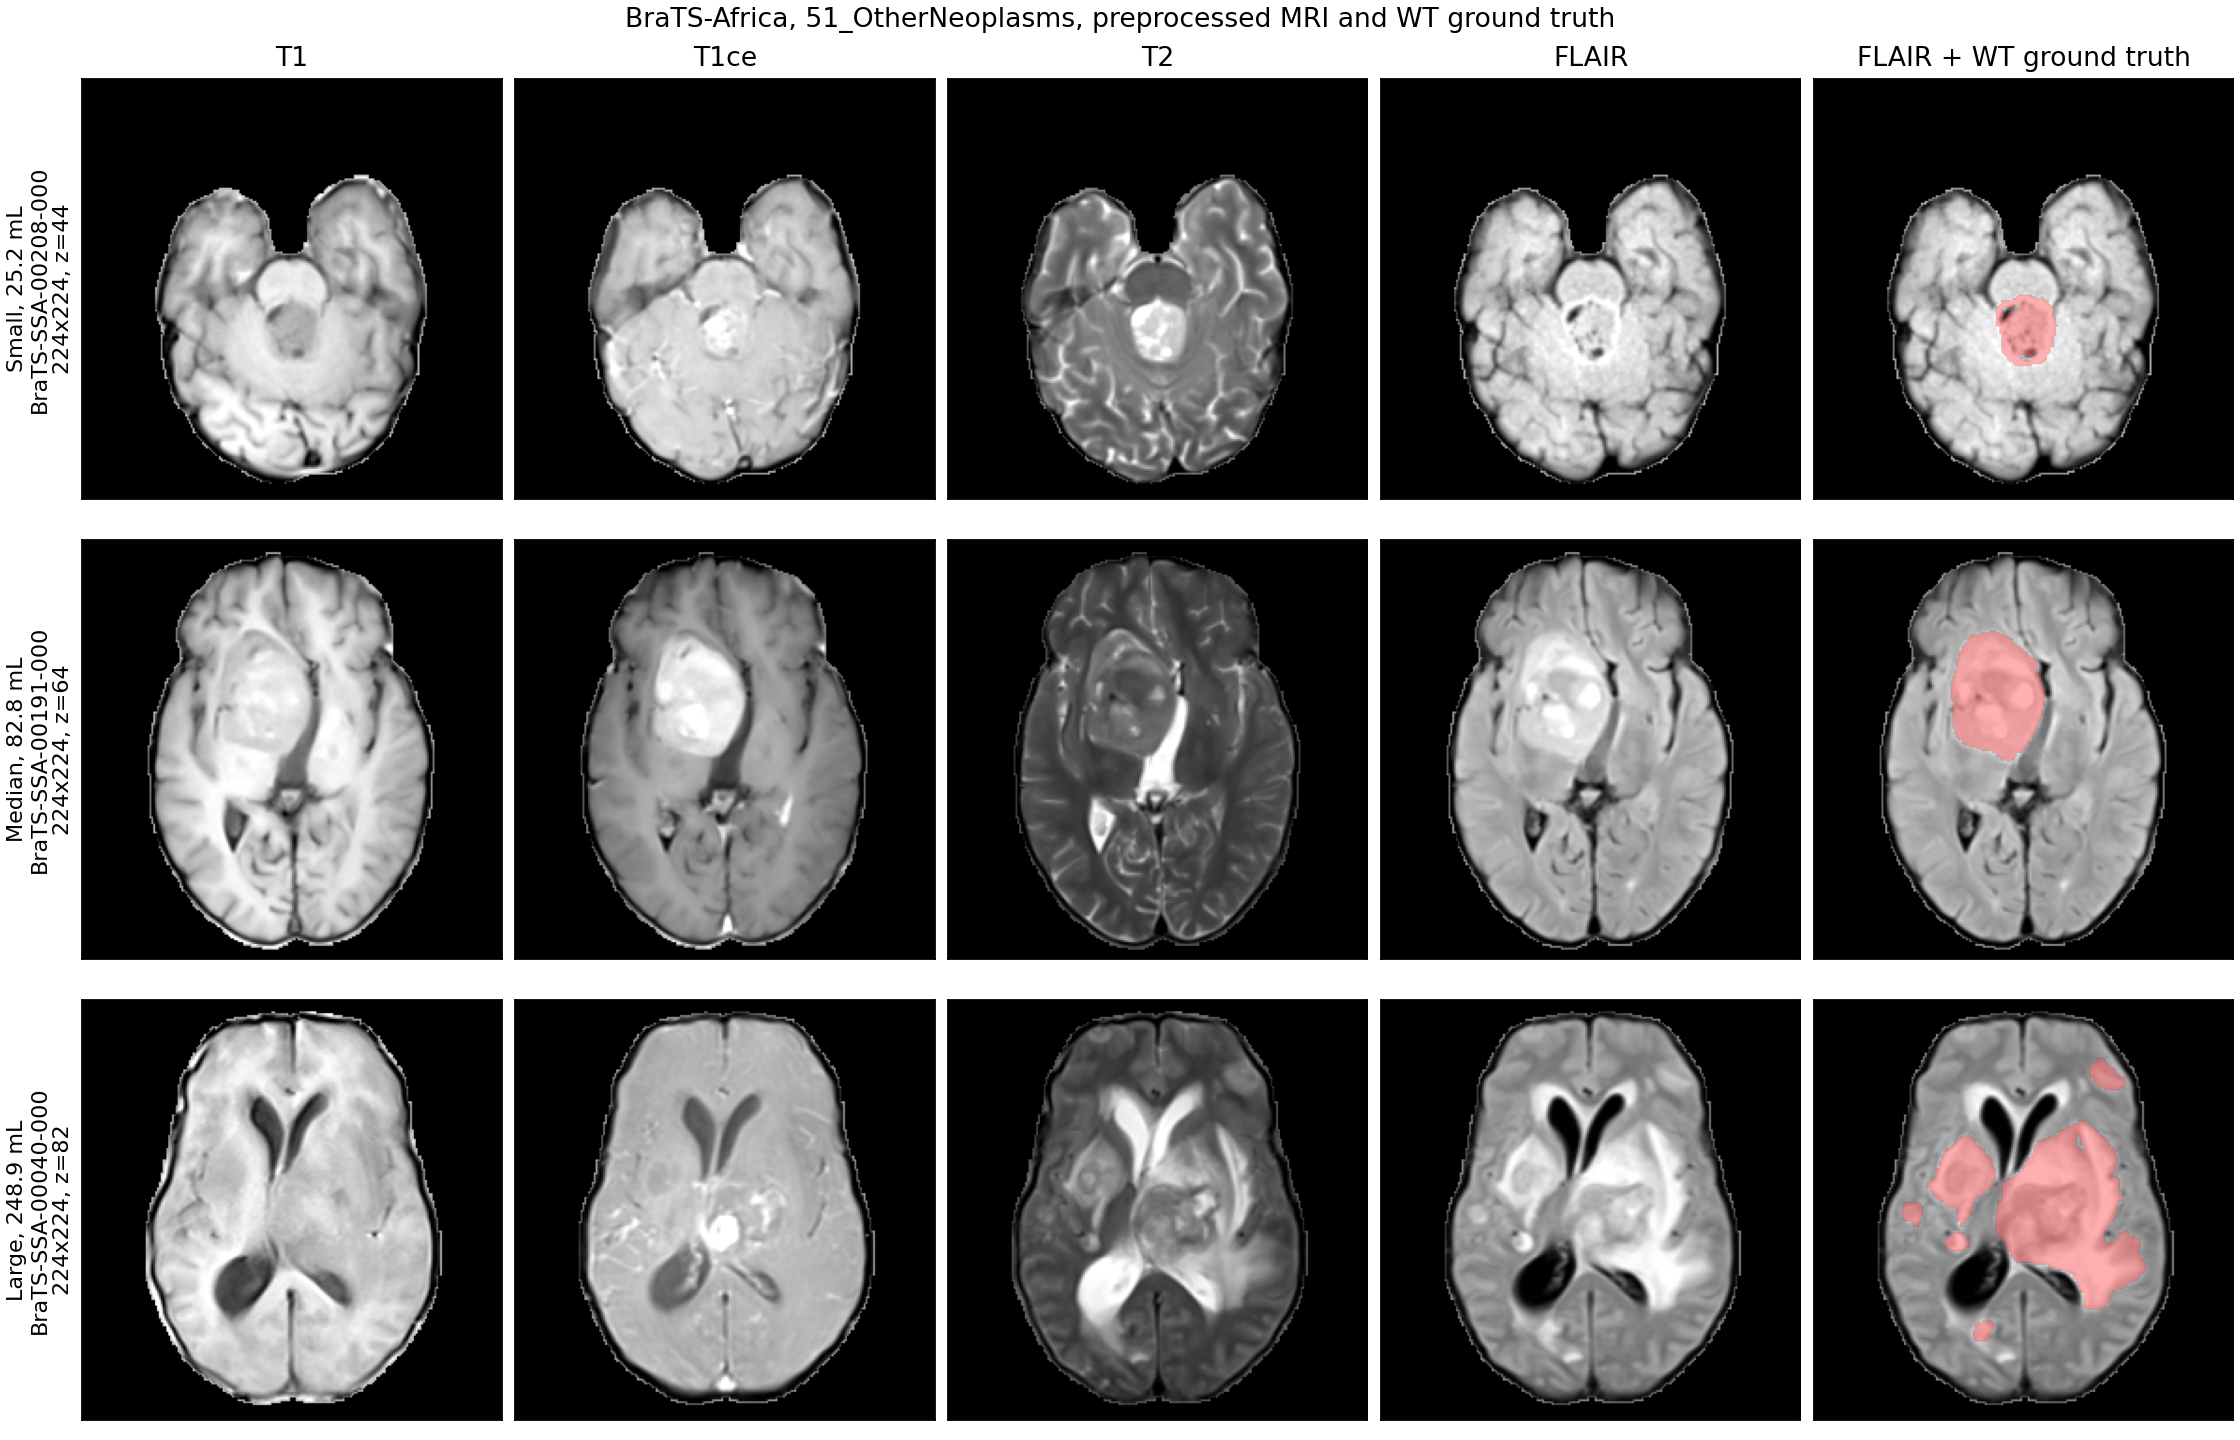

africa_npz_95_Glioma.png


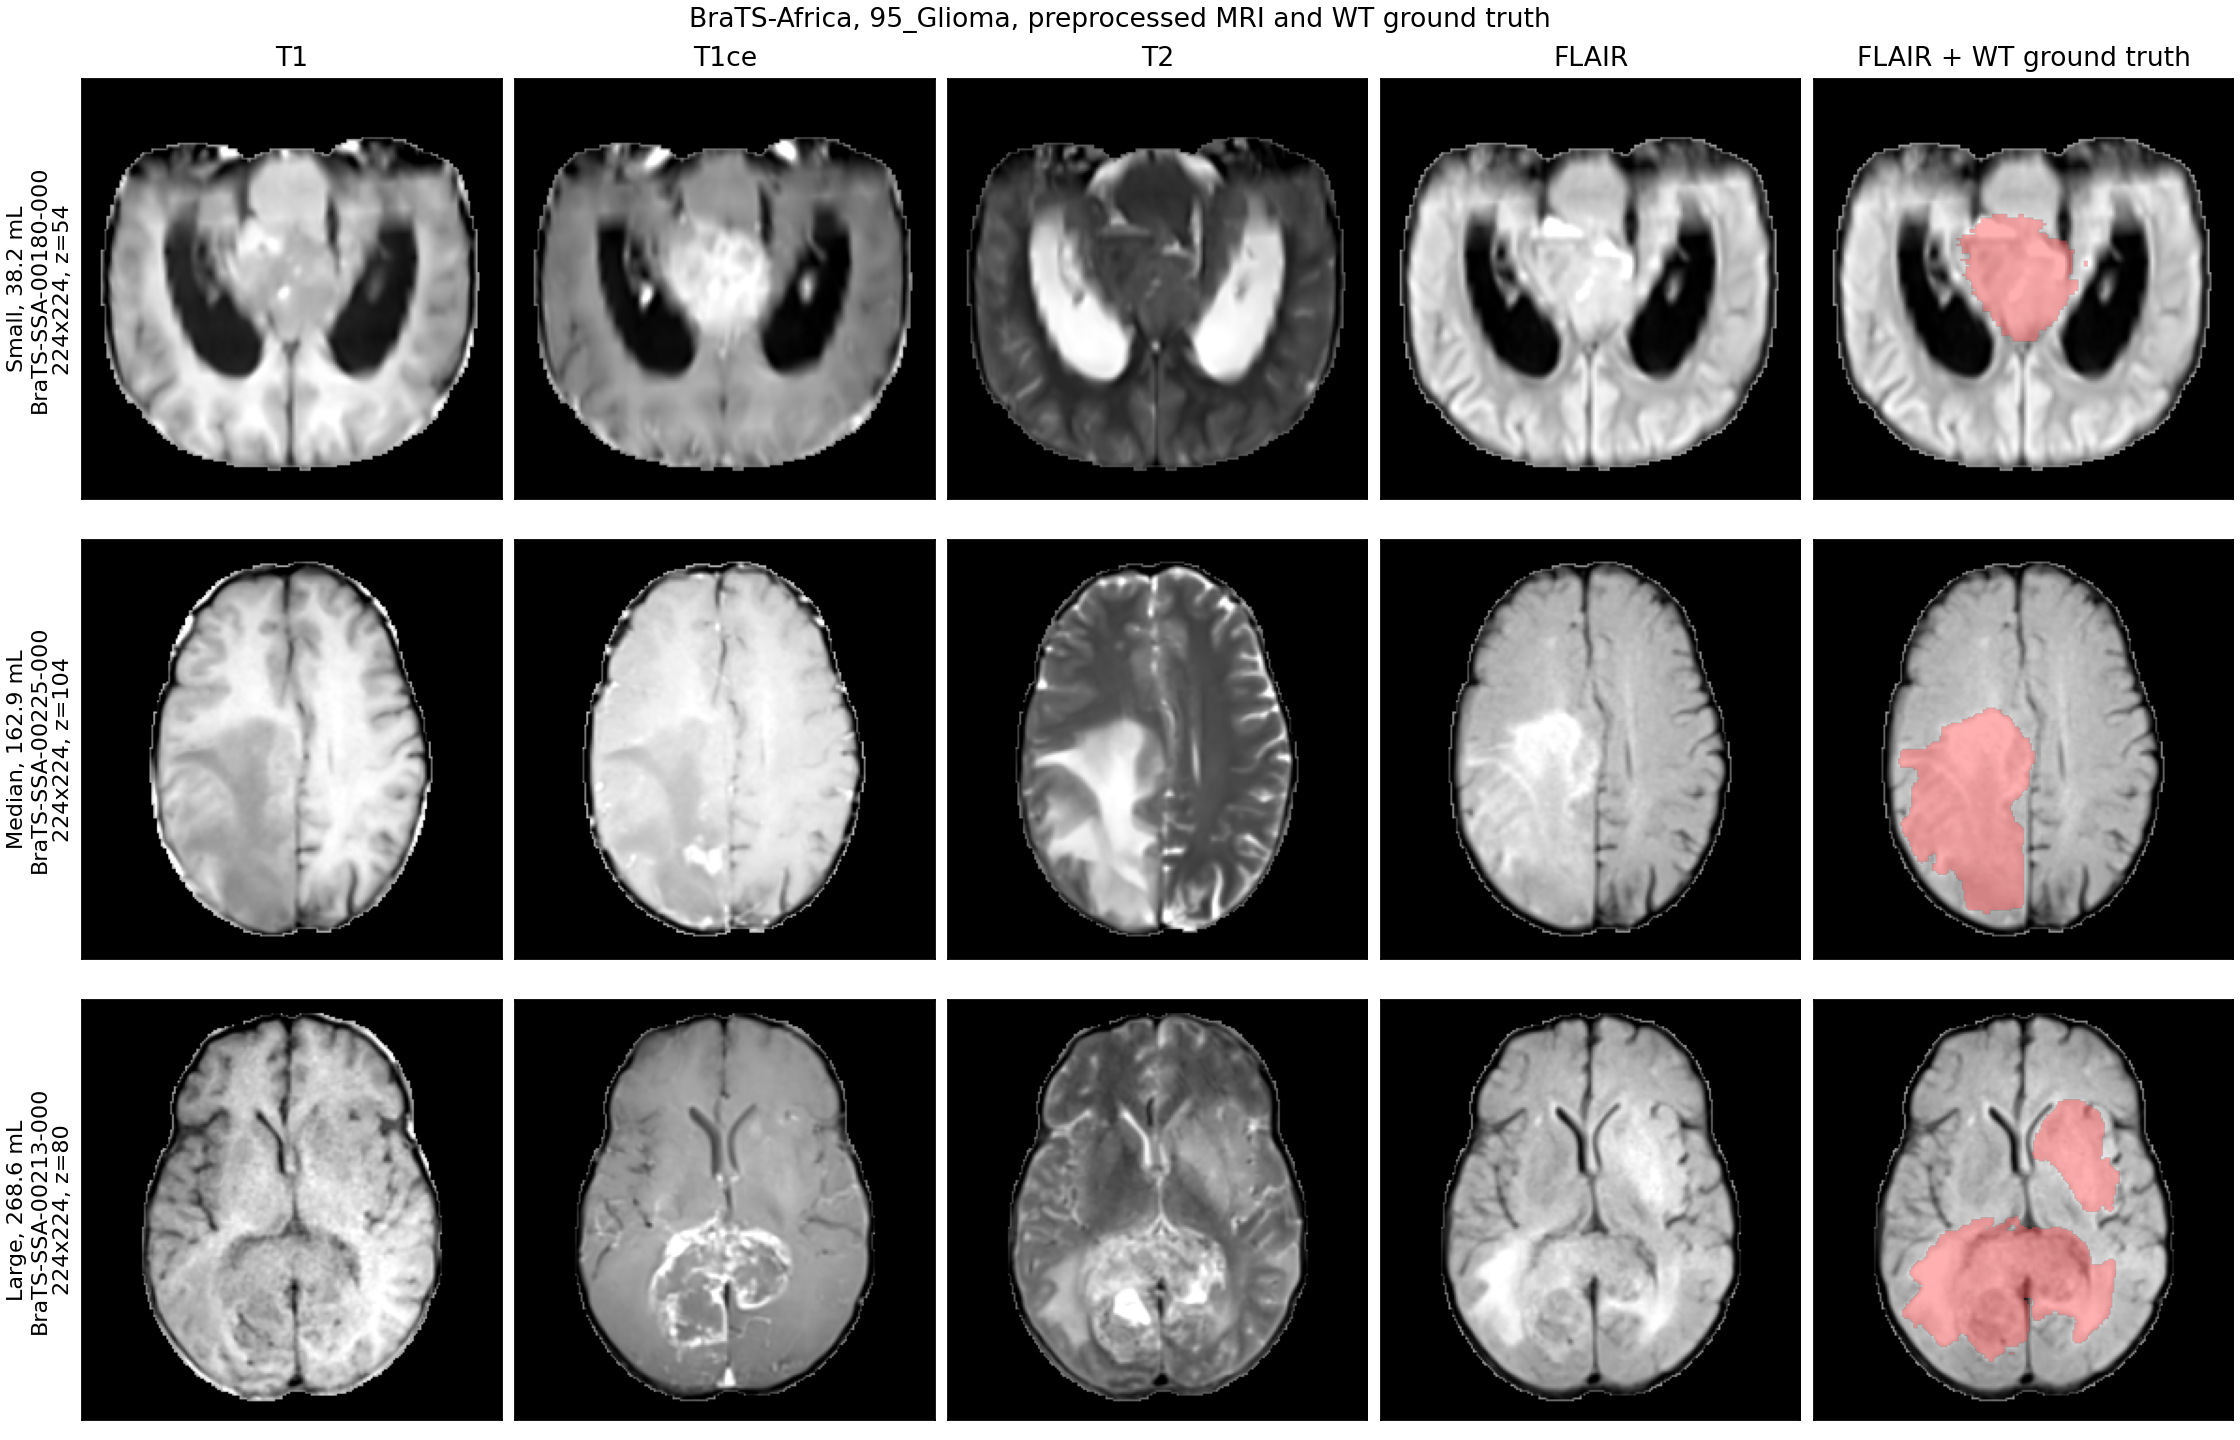

In [8]:
# 8. Vẽ sáu ca và lưu thông tin chọn ca, chọn lát.
run_module(
    'src.viz.africa_samples',
    '--data-dir', PROCESSED_DIR,
    '--out-dir', FIGURE_DIR
)

for figure in sorted(FIGURE_DIR.glob('africa_npz_*.png')):
    print(figure.name)
    display(Image(filename=str(figure), width=1100))

## 9. Lưu và tải kết quả

ZIP kết quả gồm bảng kiểm tra, thống kê WT, hai hình và danh sách ca đã chọn.
NPZ và thông tin đăng nhập không nằm trong ZIP kết quả.
Kết quả cũng đã lưu trên Drive trong thư mục được in ở ô 3.
Sau khi chạy xong, chọn File → Save a copy in Drive để giữ notebook cùng output.


In [9]:
# 9. Nén kết quả của lần chạy này và tải về máy.

import shutil

manifest = {
    'dataset': DATASET,
    'num_checked_cases': summary['num_valid_cases'],
    'image_space': 'preprocessed_224x224',
    'overlay': 'whole_tumor_ground_truth',
    'output_dir': str(OUT_DIR)
}
(OUT_DIR / 'run_manifest.json').write_text(
    json.dumps(manifest, indent=2, ensure_ascii=False), encoding='utf-8'
)
archive_path = shutil.make_archive(str(OUT_DIR), 'zip', OUT_DIR)
print('ZIP kết quả:', archive_path)

if IN_COLAB:
    from google.colab import files
    files.download(archive_path)

ZIP kết quả: /content/drive/MyDrive/brats_africa_midterm/africa_data_run01.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>